# 02. LLM Prompts, Causal Schema & Operational Knowledge (DKP)

- **Goal:** Quantify how retrieving Water Control Manual rules (`dkp.md`) changes 10-seed LLM performance.
- **Case & Window:** F.E. Walter Dam (`2021` offline replay vs USGS `01447780` / `01447800` / `01449000`).
- **Pass Criterion:** `verify_run = PASS` with `0` network calls; `dkp` beats `seasonal_target` on pool level.

*Uses offline replay of archived LLM releases (`0` API cost).*

In [1]:
import json, tempfile
from pathlib import Path
import sys
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h
from llm_reservoir_agent.workflow import load_settings

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Compare Prompts, Causal Schema & DKP Retrieval

`load_settings` pins every file by SHA-256 and enforces causal step inputs (`valid_time <= clock`, zero future inflow leakage).

In [2]:
fe = REPO_ROOT / "examples" / "fe_walter"
st = load_settings(fe / "seasonal_target.yaml", runtime_root=REPO_ROOT)
dkp = load_settings(fe / "dkp.yaml", runtime_root=REPO_ROOT)
schemas = json.loads((fe / "study" / "response_schemas.json").read_text(encoding="utf-8"))
st_keys = list(schemas["seasonal_target"]["properties"])
dkp_keys = list(schemas["dkp"]["properties"])
print("Extra DKP schema fields :", [k for k in dkp_keys if k not in st_keys])
sample_json = {
    "applicable_target_ft": 1300.0, "pool_position": "above_target",
    "intended_storage_direction": "decrease", "release_relation_to_inflow": "above_inflow",
    "operating_mode": "draw_toward_target", "rules_applied": ["R-RELEASE", "R-ZONE"],
    "reasoning": "Draw pool gently toward 1,300 ft winter conservation.", "release_cfs": 400.0,
}
print("Annotated Day-1 Causal JSON (fields ordered before release_cfs):")
print(json.dumps(sample_json, indent=2))

Extra DKP schema fields : ['operating_mode', 'rules_applied']
Annotated Day-1 Causal JSON (fields ordered before release_cfs):
{
  "applicable_target_ft": 1300.0,
  "pool_position": "above_target",
  "intended_storage_direction": "decrease",
  "release_relation_to_inflow": "above_inflow",
  "operating_mode": "draw_toward_target",
  "rules_applied": [
    "R-RELEASE",
    "R-ZONE"
  ],
  "reasoning": "Draw pool gently toward 1,300 ft winter conservation.",
  "release_cfs": 400.0
}


## 2. Replay 10-Seed Ensemble & Verify Offline

Replay `rule_based` plus 10 seeds each of **Without knowledge** (`seasonal_target`) and **With knowledge** (`dkp`) in `TemporaryDirectory()`.

In [3]:
with tempfile.TemporaryDirectory() as td:
    ens = h.replay_fe_walter_2021_ensemble(REPO_ROOT, Path(td))

df_sc, trajs, obs = ens["seed_scores"], ens["trajectories"], ens["observations"]
print("Offline verify_run:", {k: v["status"] for k, v in ens["verifications"].items()})
med = df_sc.groupby(["quantity", "condition"], sort=False)[["kge", "nse", "rmse"]].median().round(3)
print(med.to_string())
























Offline verify_run: {'without_knowledge': 'PASS', 'with_knowledge': 'PASS'}
                                                kge    nse     rmse
quantity                   condition                               
Reservoir level (01447780) rule_based         0.193 -4.904   79.027
Water release (01447800)   rule_based         0.478  0.282  896.436
Downstream flow (01449000) rule_based         0.796  0.719  920.154
Reservoir level (01447780) without_knowledge  0.852  0.693   18.016
Water release (01447800)   without_knowledge  0.696  0.500  748.139
Downstream flow (01449000) without_knowledge  0.868  0.775  822.780
Reservoir level (01447780) with_knowledge     0.873  0.744   16.458
Water release (01447800)   with_knowledge     0.616  0.252  914.551
Downstream flow (01449000) with_knowledge     0.837  0.710  933.636


## 3. Where Does Operational Knowledge Help (and Trade Off)?

Plot all 10 seeds across all 3 USGS gauges alongside 2021 interquartile (`25th–75th` pct) trajectories.

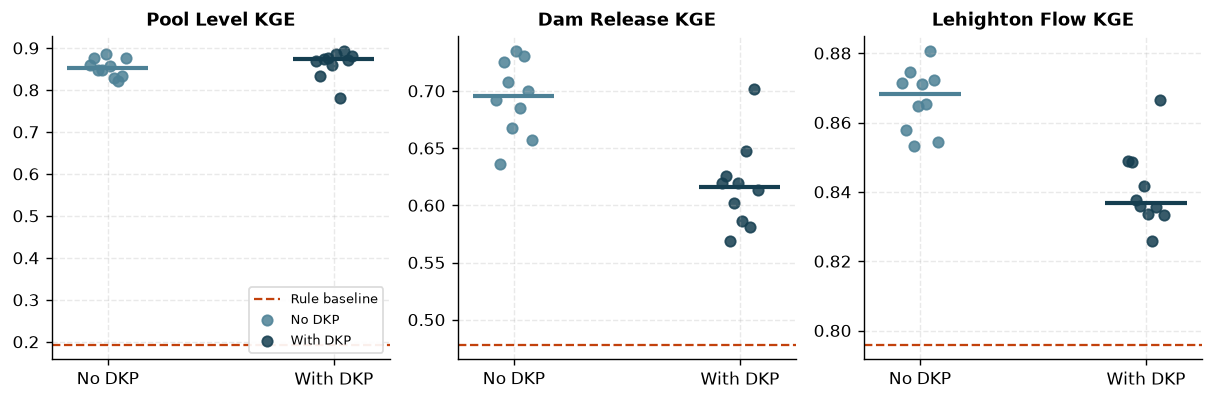

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9.8, 3.3))
gauges = [
    ("Reservoir level (01447780)", "Pool Level KGE"),
    ("Water release (01447800)", "Dam Release KGE"),
    ("Downstream flow (01449000)", "Lehighton Flow KGE"),
]
for ax, (qty, title) in zip(axes, gauges):
    sub = df_sc[df_sc["quantity"] == qty]
    r_val = float(sub.loc[sub["condition"] == "rule_based", "kge"].iloc[0])
    ax.axhline(r_val, color=C["coral"], ls="--", lw=1.3, label="Rule baseline")
    for x, (cond, lbl, col) in enumerate([("without_knowledge", "No DKP", C["slate"]), ("with_knowledge", "With DKP", C["navy"])]):
        vals = sub.loc[sub["condition"] == cond, "kge"].to_numpy()
        ax.scatter(np.full_like(vals, x) + np.linspace(-0.08, 0.08, len(vals)), vals, color=col, s=36, alpha=0.85, label=lbl)
        ax.hlines(np.median(vals), x - 0.18, x + 0.18, color=col, lw=2.4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No DKP", "With DKP"]); ax.set_title(title)
axes[0].legend(loc="lower right", fontsize=7.5); plt.tight_layout(); plt.show()

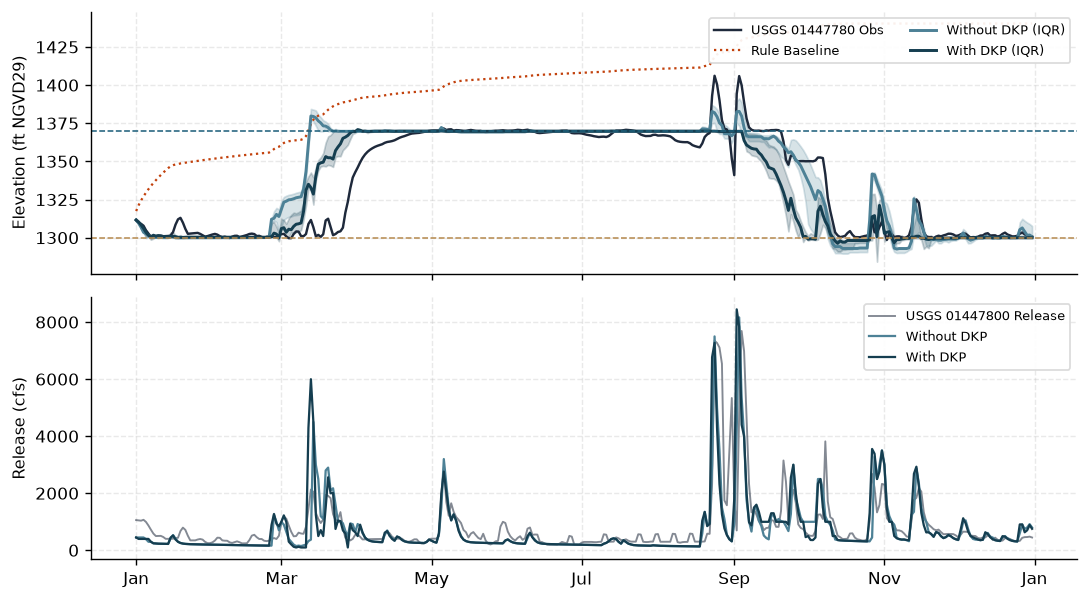

In [5]:
dates = trajs["dates"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.8, 4.9), sharex=True)
ax1.plot(obs["date_dt"], obs["water_level_ft"], color=C["obs"], lw=1.4, label="USGS 01447780 Obs")
ax1.plot(dates, trajs["rule_based"]["elev_ft"], color=C["coral"], ls=":", lw=1.3, label="Rule Baseline")
for cond, lbl, col in [("without_knowledge", "Without DKP (IQR)", C["slate"]), ("with_knowledge", "With DKP (IQR)", C["navy"])]:
    arr = np.asarray(trajs[cond]["elev_ft"])
    ax1.fill_between(dates, np.percentile(arr, 25, 0), np.percentile(arr, 75, 0), color=col, alpha=0.22)
    ax1.plot(dates, np.median(arr, 0), color=col, lw=1.7, label=lbl)
ax1.axhline(1370, color=C["teal"], ls="--", lw=0.9); ax1.axhline(1300, color=C["gold"], ls="--", lw=0.9)
ax1.set_ylabel("Elevation (ft NGVD29)"); ax1.legend(loc="upper right", ncol=2, fontsize=7.5)

ax2.plot(obs["date_dt"], obs["release_cfs"], color=C["obs"], alpha=0.55, lw=1.1, label="USGS 01447800 Release")
for cond, lbl, col in [("without_knowledge", "Without DKP", C["slate"]), ("with_knowledge", "With DKP", C["navy"])]:
    arr = np.asarray(trajs[cond]["rel_cfs"])
    ax2.plot(dates, np.median(arr, 0), color=col, lw=1.3, label=lbl)
ax2.set_ylabel("Release (cfs)"); ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax2.legend(loc="upper right", fontsize=7.5); plt.tight_layout(); plt.show()

- **Pool gain:** `dkp.md` lifts pool elevation KGE and tightens 10-seed spread vs `seasonal_target`.
- **Multi-gauge trade-off:** Tighter pool control dips raw dam-release KGE while keeping downstream flow steady.

## 4. Adapt to Your Basin (Zero-Python YAML & Live Ollama)

`study/formatter.py` is optional (imperial units only). Use the zero-Python public schema (`type: llm`, `$observation`/`$knowledge`, `reservoir-action.v1`) and run live via `ollama pull gemma4:12b`, `max_calls > 0`, and `--allow-network`.

Next: [Module 03](../03_watershed_hydrology_and_cv/03_hydrocnhs_cv_and_coupling.ipynb)